# Fase 1 — Dados

Leitura, recorte e limpeza da base Google Local 2021 (Wyoming, gastronomia), com a descrição da base e as análises que justificam as decisões do trabalho.

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from src.analises import (
    ajustar_vieses,
    decompor_variancia,
    distancia_ao_mais_proximo,
    erros_de_nota,
    ic_bootstrap,
    k_core,
    matriz_binaria,
    matriz_distancias_km,
    matriz_jaccard,
    media_entre_pares,
    suporte_vizinhos,
)
from src.dados import (
    CATEGORIAS_EXCLUIDAS,
    GRUPOS_DECLARAVEIS,
    GRUPOS_DERIVADOS,
    GRUPOS_TEMPORARIOS,
    LOCAIS_INCLUIDOS_MANUALMENTE,
    atributos_do_local,
    categoria_principal,
    contar_avaliacoes_por_local,
    copias_identicas,
    eh_gastronomia,
    indice_gini,
    ler_avaliacoes,
    ler_metadados,
    limpar_avaliacoes,
    limpar_locais,
    marcar_rajadas,
    no_recorte,
    tem_categoria_alimentacao,
)
from src.graficos import (
    COR_PRINCIPAL,
    COR_SECUNDARIA,
    ESCALA_SEQUENCIAL,
    aplicar_estilo,
    eixo_br,
    numero_br,
    salvar,
)

CAMINHO_METADADOS = "meta-Wyoming.json"
CAMINHO_AVALIACOES = "review-Wyoming.json"
PASTA_PROCESSADOS = Path("data/processed")

aplicar_estilo()


def inteiro(valor):
    return f"{valor:,}".replace(",", ".")


def percentual(valor):
    return f"{valor:.1%}".replace(".", ",")

## 1.1 Leitura

Os metadados são lidos por inteiro. As avaliações são lidas linha a linha, mantendo só os locais selecionados, o que equivale a um *inner join* por `gmap_id`. De cada avaliação ficam `user_id`, `gmap_id`, `rating`, `time` e `text`; `pics` e `resp` viram os indicadores `tem_foto` e `tem_resposta`. O nome de quem avaliou não é carregado. Nenhum tratamento é aplicado nesta etapa: notas nulas e duplicatas são tratadas na seção 1.3.

In [2]:
locais = ler_metadados(CAMINHO_METADADOS)
print(f"Linhas de metadados: {inteiro(len(locais))}")
print(f"gmap_id distintos: {inteiro(locais['gmap_id'].nunique())}")
locais.isna().sum().rename("nulos").to_frame()

Linhas de metadados: 12.088
gmap_id distintos: 12.016


,nulos
name,0
address,141
gmap_id,0
description,10400
latitude,0
longitude,0
category,88
avg_rating,0
num_of_reviews,0
price,10395


In [3]:
contagem = contar_avaliacoes_por_local(CAMINHO_AVALIACOES)
fora_dos_metadados = sum(n for gmap_id, n in contagem.items() if gmap_id not in set(locais["gmap_id"]))
print(f"Linhas no arquivo de avaliações: {inteiro(sum(contagem.values()))}")
print(f"Locais com avaliação: {inteiro(len(contagem))}")
print(f"Avaliações de locais fora dos metadados: {inteiro(fora_dos_metadados)}")

Linhas no arquivo de avaliações: 1.141.421
Locais com avaliação: 12.016
Avaliações de locais fora dos metadados: 0


## 1.2 Recorte pela categoria principal

A **categoria principal** é a primeira da lista que não seja `Caterer`, para que um restaurante cuja lista começa em `Caterer` continue no recorte. O local entra se ela for de alimentação: casa com o padrão de palavras e não está na lista de exclusão. Uma categoria secundária de comida não basta; é isso que deixa de fora hotéis, postos e mercados que têm restaurante ou lanchonete. Locais de comida com categoria principal atípica entram por uma lista manual.

As contagens desta seção são das linhas brutas, antes da limpeza da seção 1.3. A lista de `gmap_id` repetidos nos metadados é tratada aqui só para não contar o mesmo local duas vezes.

In [4]:
catalogo = locais.drop_duplicates("gmap_id").copy()
catalogo["avaliacoes"] = catalogo["gmap_id"].map(contagem).fillna(0).astype(int)
catalogo["categoria_principal"] = catalogo["category"].map(categoria_principal)
catalogo["pela_regra"] = catalogo["category"].map(eh_gastronomia)
catalogo["no_recorte"] = no_recorte(catalogo)
catalogo["alguma_comida"] = catalogo["category"].map(tem_categoria_alimentacao)

pd.DataFrame(
    {
        "locais": [
            len(catalogo),
            catalogo["pela_regra"].sum(),
            (catalogo["no_recorte"] & ~catalogo["pela_regra"]).sum(),
            catalogo["no_recorte"].sum(),
        ],
        "avaliações": [
            catalogo["avaliacoes"].sum(),
            catalogo.loc[catalogo["pela_regra"], "avaliacoes"].sum(),
            catalogo.loc[catalogo["no_recorte"] & ~catalogo["pela_regra"], "avaliacoes"].sum(),
            catalogo.loc[catalogo["no_recorte"], "avaliacoes"].sum(),
        ],
    },
    index=["Arquivo inteiro", "Pela regra", "Inclusão manual", "Recorte"],
)

,locais,avaliações
Arquivo inteiro,12016,1141421
Pela regra,1855,431165
Inclusão manual,8,2753
Recorte,1863,433918


In [5]:
def resumo_por_categoria(tabela):
    return (
        tabela.groupby("categoria_principal")
        .agg(locais=("gmap_id", "size"), avaliacoes=("avaliacoes", "sum"))
        .sort_values("avaliacoes", ascending=False)
    )


with pd.option_context("display.max_rows", None):
    display(resumo_por_categoria(catalogo[catalogo["no_recorte"]]))

,locais,avaliacoes
categoria_principal,,
Fast food restaurant,152,74634
Restaurant,250,46063
Mexican restaurant,103,34442
American restaurant,115,31493
Steak house,50,26857
Pizza restaurant,94,21727
Bar & grill,82,19605
Coffee shop,110,16243
Bar,169,14804


In [6]:
rejeitadas = catalogo[~catalogo["no_recorte"]]
excluidas = rejeitadas[rejeitadas["categoria_principal"].str.lower().isin(CATEGORIAS_EXCLUIDAS)]
print("Rejeitadas pela lista de exclusão:")
display(resumo_por_categoria(excluidas))
print(f"Categorias principais rejeitadas: {inteiro(rejeitadas['categoria_principal'].nunique())}. As 20 com mais avaliações:")
resumo_por_categoria(rejeitadas).head(20)

Rejeitadas pela lista de exclusão:


,locais,avaliacoes
categoria_principal,,
Bed & breakfast,10,288
Health food store,10,163
Food bank,5,144
Catering food and drink supplier,2,33
Wholesale food store,1,14
BBQ area,1,8
Restaurant supply store,1,8
Hookah bar,1,1


Categorias principais rejeitadas: 1.166. As 20 com mais avaliações:


,locais,avaliacoes
categoria_principal,,
Hotel,214,77841
Department store,59,31866
Truck stop,40,29607
Grocery store,100,23688
Cell phone store,41,18075
Park,241,16352
Motel,86,13776
Gas station,281,13510
Tourist attraction,124,13485


In [7]:
fora_com_comida = catalogo[~catalogo["no_recorte"] & catalogo["alguma_comida"]]
print(f"Fora do recorte, com alguma categoria de comida: {inteiro(len(fora_com_comida))} locais, "
      f"{inteiro(fora_com_comida['avaliacoes'].sum())} avaliações")
display(resumo_por_categoria(fora_com_comida).head(20))
print("Os 12 locais com mais avaliações nesse grupo:")
fora_com_comida.sort_values("avaliacoes", ascending=False).head(12)[["name", "category", "avaliacoes"]]

Fora do recorte, com alguma categoria de comida: 151 locais, 31.412 avaliações


,locais,avaliacoes
categoria_principal,,
Hotel,14,12488
Truck stop,2,3958
Grocery store,7,1795
General store,2,1567
Resort hotel,5,1527
Book store,4,1189
Liquor store,11,1169
Bowling alley,6,1110
Lodge,4,861


Os 12 locais com mais avaliações nesse grupo:


,name,category,avaliacoes
12071,Little America Hotel - Wyoming,"[Hotel, Grill, Bar, Convenience store, Deli, D...",5928
11859,Little America Hotel & Resort - Cheyenne,"[Hotel, Bar, Convention center, Event venue, G...",2418
11721,Akal Travel Center,"[Truck stop, Armenian restaurant, Gas station,...",2393
12072,Stinker I-80 Travel Plaza & Restaurant,"[Truck stop, Convenience store, Gas station, R...",1565
12055,Canyon Village - General Store,"[General store, Clothing store, Diner, Gift sh...",1534
11396,Barnes & Noble,"[Book store, Cafe, Childrens book store, Hobby...",1005
11379,The Historic Plains Hotel & Restaurant,"[Hotel, Restaurant]",908
11751,Jackson Whole Grocer & Cafe,"[Grocery store, Coffee shop, Deli, Fruit and v...",898
11769,Bull Moose Lodge & Saloon,"[Lodge, American restaurant, Bar & grill, Liqu...",638
9817,Rustic Inn Creekside Resort & Spa at Jackson Hole,"[Hotel, Event venue, Lodge, Resort hotel, Rest...",638


In [8]:
incluidos = catalogo[catalogo["gmap_id"].isin(LOCAIS_INCLUIDOS_MANUALMENTE)]
print("Incluídos manualmente:")
display(incluidos.sort_values("avaliacoes", ascending=False)[["name", "category", "avaliacoes"]])

nomes_fora = ["Alf's Pub", "Saddle Lite Saloon", "Pizza Ranch FunZone Arcade", "Black Gold Grille and Event Venue",
              "Galloway's Pub & Bowling alley", "Wyoming Downs OTB Evanston"]
print("Examinados e mantidos fora:")
catalogo[catalogo["name"].isin(nomes_fora)].sort_values("avaliacoes", ascending=False)[["name", "category", "avaliacoes", "no_recorte"]]

Incluídos manualmente:


,name,category,avaliacoes
10298,Bar J Chuckwagon Suppers,"[Dinner theater, Restaurant, Steak house]",1066
10860,The Outlaw Saloon,"[Concert hall, Bar, Night club]",678
11321,Yellowstone Garage,"[Event venue, Bar]",498
11547,The Cody Cattle Company,"[Dinner theater, Bar, Live music venue, Restau...",373
4359,Bar J Chuckwagon,[Dinner theater],52
3046,Pretzelmaker,"[Pretzel store, Fast food restaurant]",44
11016,Sunset House Restaurant,"[Banquet hall, Restaurant]",26
10542,Pretzelmaker,"[Pretzel store, Fast food restaurant]",16


Examinados e mantidos fora:


,name,category,avaliacoes,no_recorte
5284,Alf's Pub,[Liquor store],278,False
11851,Wyoming Downs OTB Evanston,"[Off track betting shop, Bar]",134,False
5133,Saddle Lite Saloon,[Beauty salon],98,False
9476,Pizza Ranch FunZone Arcade,[Video arcade],95,False
4342,Black Gold Grille and Event Venue,[Event venue],68,False
8609,Galloway's Pub & Bowling alley,"[Night club, Bar]",44,False


**Decisões da inspeção:**

- **Inclusão manual:** só entram locais cuja atividade principal é servir comida ou bebida, confirmada nos comentários, e que tenham categoria de comida ou sejam Dinner theater. Além dos dois exemplos do plano, entraram The Cody Cattle Company e a segunda ficha do Bar J (Dinner theater), Yellowstone Garage, Sunset House Restaurant e duas unidades da Pretzelmaker. Por isso a lista é de locais, e não das categorias Dinner theater e Concert hall.
- **Fora, apesar do nome:** Alf's Pub, Saddle Lite Saloon, Pizza Ranch FunZone Arcade e Black Gold Grille parecem servir comida ou bebida, mas suas categorias descrevem outro negócio (loja de bebidas, salão de beleza, fliperama, espaço de eventos). Como o conteúdo vem das categorias, o vetor desses locais seria enganoso.
- **Fora, pela atividade principal:** hotéis, truck stops, mercados, boliches e casas de apostas, mesmo com bar ou restaurante, como Galloway's Pub & Bowling alley e Wyoming Downs OTB.
- **Ruído aceito:** a regra também aceita alguns locais pequenos que não são restaurantes típicos, como cafeterias de escola e uma loja classificada como Food court. Eles têm poucas avaliações e continuam no recorte, para manter a regra simples.

In [9]:
avaliacoes = ler_avaliacoes(CAMINHO_AVALIACOES, catalogo.loc[catalogo["no_recorte"], "gmap_id"])
print(f"Avaliações lidas no recorte: {inteiro(len(avaliacoes))}")
print(f"Com foto: {inteiro(avaliacoes['tem_foto'].sum())}")
print(f"Com resposta do local: {inteiro(avaliacoes['tem_resposta'].sum())}")
avaliacoes.isna().sum().rename("nulos").to_frame()

Avaliações lidas no recorte: 433.918
Com foto: 11.092
Com resposta do local: 39.229


,nulos
user_id,0
gmap_id,0
rating,0
time,0
text,177319
tem_foto,0
tem_resposta,0


## 1.3 Limpeza

Os arquivos brutos não são alterados. A limpeza vale para os locais e as avaliações do recorte, e o resultado é gravado em `data/processed/`.

- **Avaliações:** saem as sem nota ou sem usuário e as duplicatas exatas; se o mesmo usuário avaliou o mesmo local mais de uma vez, fica a mais recente. `time` vira `data`, `ano` e `mes`, e `tem_texto` marca as avaliações com comentário. Textos ausentes e traduzidos continuam.
- **Locais:** fica uma cópia de cada `gmap_id`, depois de conferir que as cópias são idênticas. Cidade e CEP vêm do endereço. Coordenadas fora de Wyoming são anuladas. `preco_nivel` conta os símbolos `$` ou `₩`.
- **Fechados:** `fechado_perm` e `fechado_temp` vêm só do texto de `state`. As avaliações desses locais continuam, pois mostram gosto, mas eles não serão recomendados. `state` ausente não significa fechado, e "Closed ⋅ Opens" é só o horário do momento da coleta.
- **`avg_rating_google` e `num_of_reviews_google`:** servem só para conferência. Incluem o futuro, então não são *features*.

In [10]:
limpas, funil_avaliacoes = limpar_avaliacoes(avaliacoes)

selecionados = locais[no_recorte(locais)]
locais_limpos = limpar_locais(selecionados)
com_avaliacao = locais_limpos["gmap_id"].isin(limpas["gmap_id"])
locais_limpos = locais_limpos[com_avaliacao].reset_index(drop=True)

sem_categoria = catalogo["category"].isna().sum()
funil_locais = pd.DataFrame(
    [
        ("Linhas de metadados", len(locais), 0),
        ("gmap_id repetido", catalogo.shape[0], len(locais) - len(catalogo)),
        ("Sem categoria", catalogo.shape[0] - sem_categoria, sem_categoria),
        ("Com categoria, fora do recorte", catalogo["no_recorte"].sum(), catalogo.shape[0] - sem_categoria - catalogo["no_recorte"].sum()),
        ("Sem avaliação depois da limpeza", len(locais_limpos), (~com_avaliacao).sum()),
    ],
    columns=["etapa", "linhas", "removidas"],
)
print(f"Cópias de gmap_id idênticas no arquivo inteiro: {copias_identicas(locais)}")
print(f"gmap_id repetidos dentro do recorte: {inteiro(selecionados['gmap_id'].duplicated().sum())}")
display(funil_locais)
funil_avaliacoes

Cópias de gmap_id idênticas no arquivo inteiro: True
gmap_id repetidos dentro do recorte: 4


,etapa,linhas,removidas
0,Linhas de metadados,12088,0
1,gmap_id repetido,12016,72
2,Sem categoria,11931,85
3,"Com categoria, fora do recorte",1863,10068
4,Sem avaliação depois da limpeza,1863,0


,etapa,linhas,removidas
0,Avaliações do recorte,433918,0
1,Sem nota ou sem usuário,433918,0
2,Duplicatas exatas,429622,4296
3,"Mesmo usuário e local, fica a mais recente",429622,0


In [11]:
traduzidos = limpas["text"].str.contains("(Translated by Google)", regex=False, na=False)
print(f"Sem texto: {inteiro((~limpas['tem_texto']).sum())} ({percentual((~limpas['tem_texto']).mean())})")
print(f"Traduzidos automaticamente: {inteiro(traduzidos.sum())}")
print(f"Período: {limpas['data'].min():%d/%m/%Y} a {limpas['data'].max():%d/%m/%Y}")
limpas["rating"].value_counts().sort_index().rename("avaliações").to_frame()

Sem texto: 177.267 (41,3%)
Traduzidos automaticamente: 3.290
Período: 27/03/2008 a 04/09/2021


,avaliações
rating,
1,31149
2,19277
3,43820
4,96336
5,239040


In [12]:
media_na_base = limpas.groupby("gmap_id")["rating"].mean()
consistencia = locais_limpos.set_index("gmap_id")["avg_rating_google"].corr(media_na_base)

print(f"Sem cidade: {inteiro(locais_limpos['cidade'].isna().sum())}; cidades distintas: {inteiro(locais_limpos['cidade'].nunique())}")
print(f"Sem CEP: {inteiro(locais_limpos['cep'].isna().sum())}")
print(f"Coordenadas anuladas: {inteiro(locais_limpos['latitude'].isna().sum())}")
print(f"Preço com ₩: {inteiro(locais_limpos['price'].str.contains('₩', na=False).sum())}")
print(f"Fechados: permanentemente {inteiro(locais_limpos['fechado_perm'].sum())}, temporariamente {inteiro(locais_limpos['fechado_temp'].sum())}")
print(f"Correlação entre avg_rating_google e a média na base: {consistencia:.3f}".replace(".", ","))

display(locais_limpos["preco_nivel"].value_counts(dropna=False).sort_index().rename("locais").to_frame())
locais_limpos.loc[locais_limpos["cidade"].isna(), ["name", "address", "latitude", "longitude"]]

Sem cidade: 7; cidades distintas: 115
Sem CEP: 6
Coordenadas anuladas: 0
Preço com ₩: 16
Fechados: permanentemente 205, temporariamente 33
Correlação entre avg_rating_google e a média na base: 0,991


,locais
preco_nivel,
1.0,611
2.0,537
3.0,23
4.0,1
NaN,691


,name,address,latitude,longitude
188,Christie’s Cupcakes,NaN,41.147532,-104.767405
208,Cluck Truck,NaN,41.025359,-109.052621
411,Nom Nom Doughnuts,NaN,43.475140,-110.851555
424,Hairy's Mobile Ice Cream Truck,NaN,41.396275,-108.907263
602,Coyote Blue Coffee Drive Thru,NaN,43.540324,-109.643289
675,Savageton Bar,"Savageton Bar, Wyoming 82718",43.866572,-105.791048
770,Snowy Elk Coffee Company,NaN,41.147532,-104.767405


In [13]:
em_rajada = marcar_rajadas(limpas)
minuto = limpas["data"].dt.floor("min")
rajadas = (
    limpas[em_rajada]
    .groupby(["user_id", minuto[em_rajada]])
    .agg(
        avaliacoes=("rating", "size"),
        notas_distintas=("rating", "nunique"),
        nota_media=("rating", "mean"),
        textos=("text", "count"),
        textos_distintos=("text", "nunique"),
    )
)
constantes = rajadas["notas_distintas"].eq(1)

print(f"Avaliações em rajada: {inteiro(em_rajada.sum())} ({percentual(em_rajada.mean())})")
print(f"Rajadas: {inteiro(len(rajadas))}, de {inteiro(rajadas.index.get_level_values('user_id').nunique())} usuários")
print(f"Rajadas com nota constante: {inteiro(constantes.sum())} ({percentual(constantes.mean())}), "
      f"somando {inteiro(rajadas.loc[constantes, 'avaliacoes'].sum())} avaliações")
print(f"Rajadas com texto repetido: {inteiro((rajadas['textos'] > rajadas['textos_distintos']).sum())}")

fora_de_rajada = limpas[~em_rajada].groupby("user_id")["rating"].agg(["size", "nunique"])
comparacao = fora_de_rajada[fora_de_rajada["size"] >= 5]
print(f"Fora de rajada, usuários com 5 ou mais avaliações e nota constante: {percentual(comparacao['nunique'].eq(1).mean())}")

display(rajadas.loc[constantes, "nota_media"].value_counts().sort_index().rename("rajadas constantes").to_frame())
pd.DataFrame(
    {
        "em rajada": limpas.loc[em_rajada, "rating"].value_counts(normalize=True).sort_index(),
        "fora de rajada": limpas.loc[~em_rajada, "rating"].value_counts(normalize=True).sort_index(),
    }
).round(3)

Avaliações em rajada: 5.832 (1,4%)
Rajadas: 993, de 822 usuários
Rajadas com nota constante: 209 (21,0%), somando 1.199 avaliações
Rajadas com texto repetido: 5


Fora de rajada, usuários com 5 ou mais avaliações e nota constante: 11,7%


,rajadas constantes
nota_media,
1.0,2
3.0,13
4.0,14
5.0,180


,em rajada,fora de rajada
rating,,
1,0.027,0.073
2,0.042,0.045
3,0.195,0.101
4,0.268,0.224
5,0.467,0.558


**Decisão sobre as rajadas:** todas continuam, inclusive as de nota constante. Elas são mais frequentes que a nota constante fora de rajada, mas somam muito pouco da base, quase nunca repetem texto e têm menos notas 5 que o restante, o que não sugere avaliações forjadas. Parecem pessoas registrando de uma vez os locais que visitaram.

In [14]:
PASTA_PROCESSADOS.mkdir(parents=True, exist_ok=True)
limpas.to_parquet(PASTA_PROCESSADOS / "avaliacoes.parquet", index=False)
locais_limpos.to_parquet(PASTA_PROCESSADOS / "locais.parquet", index=False)

for nome in ["avaliacoes.parquet", "locais.parquet"]:
    caminho = PASTA_PROCESSADOS / nome
    tabela = pd.read_parquet(caminho)
    tamanho = f"{caminho.stat().st_size / 1e6:.1f}".replace(".", ",")
    resumo = hashlib.sha256(caminho.read_bytes()).hexdigest()[:16]
    print(f"{nome}: {inteiro(len(tabela))} linhas, {tabela.shape[1]} colunas, {tamanho} MB, sha256 {resumo}")

avaliacoes.parquet: 429.622 linhas, 10 colunas, 29,4 MB, sha256 6efa126e4cc75761
locais.parquet: 1.863 linhas, 19 colunas, 0,3 MB, sha256 8968127add047869


## 1.4 Descrição da base

Descrição da base limpa no **período inteiro**, para o slide c. Apenas esta seção usa o período inteiro: as análises que orientam decisões, na seção 1.5, olham só os dados anteriores ao corte de teste.

In [15]:
base = limpas.merge(locais_limpos[["gmap_id", "cidade", "categoria_principal"]], on="gmap_id", validate="many_to_one")
usuarios = limpas["user_id"].nunique()
quantidade_locais = limpas["gmap_id"].nunique()
esparsidade = 1 - len(limpas) / (usuarios * quantidade_locais)

pd.DataFrame(
    {
        "valor": [
            inteiro(len(limpas)),
            inteiro(usuarios),
            inteiro(quantidade_locais),
            inteiro(locais_limpos["cidade"].nunique()),
            f"{limpas['data'].min():%d/%m/%Y} a {limpas['data'].max():%d/%m/%Y}",
            numero_br(limpas["rating"].mean(), 2),
            numero_br(limpas["rating"].std(), 2),
            numero_br(len(limpas) / usuarios, 2),
            numero_br(len(limpas) / quantidade_locais, 1),
            f"{esparsidade:.3%}".replace(".", ","),
        ]
    },
    index=[
        "Avaliações",
        "Usuários",
        "Locais",
        "Cidades",
        "Período",
        "Nota média",
        "Desvio-padrão da nota",
        "Avaliações por usuário (média)",
        "Avaliações por local (média)",
        "Esparsidade",
    ],
)

,valor
Avaliações,429.622
Usuários,175.278
Locais,1.863
Cidades,115
Período,27/03/2008 a 04/09/2021
Nota média,"4,15"
Desvio-padrão da nota,"1,21"
Avaliações por usuário (média),"2,45"
Avaliações por local (média),"230,6"
Esparsidade,"99,868%"


**Visão geral:** são 429.622 avaliações de 175.278 usuários em 1.863 locais de 115 cidades. Com 99,868% de esparsidade, quase toda combinação de usuário e local está vazia, o que limita qualquer técnica que dependa de histórico em comum.

Notas 4 ou 5: 78,1%


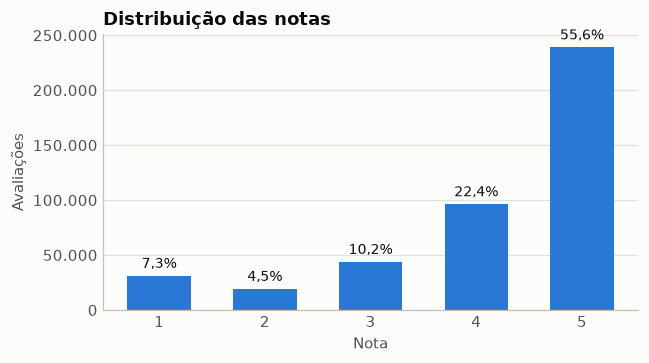

In [16]:
notas = limpas["rating"].value_counts().sort_index()
print(f"Notas 4 ou 5: {percentual((limpas['rating'] >= 4).mean())}")

figura, eixo = plt.subplots(figsize=(6, 3.4))
barras = eixo.bar(notas.index, notas.values, color=COR_PRINCIPAL, width=0.6)
eixo.bar_label(barras, labels=[percentual(valor / len(limpas)) for valor in notas.values], padding=3, fontsize=9)
eixo.set_title("Distribuição das notas")
eixo.set_xlabel("Nota")
eixo.set_ylabel("Avaliações")
eixo.grid(axis="x", visible=False)
eixo_br(eixo.yaxis)
figura.tight_layout()
salvar(figura, "10_distribuicao_notas")
plt.show()

**Notas:** a distribuição é assimétrica: 78,1% das avaliações têm nota 4 ou 5, e a nota 5 sozinha tem 55,6%. Com a média em 4,15, notas de 1 a 3 são o sinal mais raro, o que apoia considerar relevante a nota 4 ou maior.

Usuários com uma única avaliação: 115.717 (66,0%)
Máximo de avaliações de um usuário: 136


,usuários,fração dos usuários,fração das avaliações
com ao menos k avaliações,,,
1,175278,1.000,1.000
2,59561,0.340,0.731
3,34864,0.199,0.616
5,18300,0.104,0.486
10,7344,0.042,0.323
20,2282,0.013,0.166
50,176,0.001,0.027


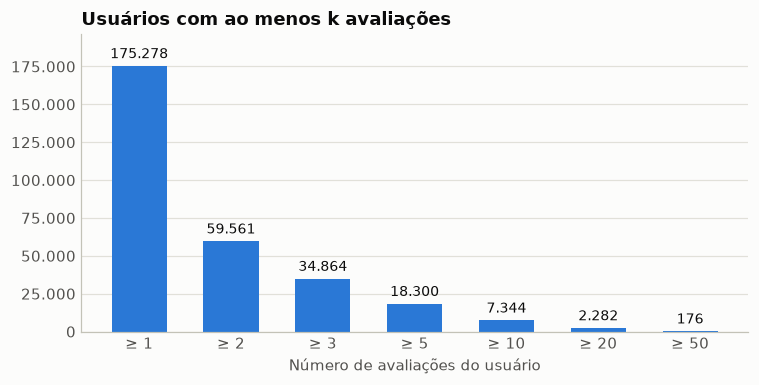

In [17]:
avaliacoes_por_usuario = limpas.groupby("user_id").size()
limiares = [1, 2, 3, 5, 10, 20, 50]
atividade = pd.DataFrame(
    {
        "usuários": [(avaliacoes_por_usuario >= k).sum() for k in limiares],
        "fração dos usuários": [(avaliacoes_por_usuario >= k).mean() for k in limiares],
        "fração das avaliações": [avaliacoes_por_usuario[avaliacoes_por_usuario >= k].sum() / len(limpas) for k in limiares],
    },
    index=pd.Index(limiares, name="com ao menos k avaliações"),
)
print(f"Usuários com uma única avaliação: {inteiro((avaliacoes_por_usuario == 1).sum())} ({percentual((avaliacoes_por_usuario == 1).mean())})")
print(f"Máximo de avaliações de um usuário: {inteiro(avaliacoes_por_usuario.max())}")
display(atividade.round(3))

figura, eixo = plt.subplots(figsize=(7, 3.6))
rotulos = [f"≥ {k}" for k in limiares]
barras = eixo.bar(rotulos, atividade["usuários"], color=COR_PRINCIPAL, width=0.6)
eixo.bar_label(barras, labels=[inteiro(valor) for valor in atividade["usuários"]], padding=3, fontsize=9)
eixo.set_title("Usuários com ao menos k avaliações")
eixo.set_xlabel("Número de avaliações do usuário")
eixo.set_ylim(0, atividade["usuários"].max() * 1.12)
eixo.grid(axis="x", visible=False)
eixo_br(eixo.yaxis)
figura.tight_layout()
salvar(figura, "11_atividade_usuarios")
plt.show()

**Atividade dos usuários:** 66,0% dos usuários têm uma única avaliação. Só 19,9% têm 3 ou mais, mas eles concentram 61,6% das avaliações. Em média são 2,45 avaliações por usuário, e o mais ativo tem 136. A maioria das pessoas tem pouquíssimo histórico, o que torna importante o cenário de usuário novo; a seção 1.5 mede quanto ele pesa ao longo do tempo.

Índice de Gini: 0,587
Mediana de avaliações por local: 123; média: 230,6


,locais,fração das avaliações
1% mais avaliados,19,0.076
10% mais avaliados,187,0.409
20% mais avaliados,373,0.612
50% mais avaliados,932,0.895


,avaliacoes,name,cidade,categoria_principal
0,2598,Texas Roadhouse,Cheyenne,Steak house
1,2408,"Wyoming's Rib & Chop House, Cheyenne",Cheyenne,Steak house
2,2310,Chick-fil-A,Cheyenne,Fast food restaurant
3,2005,Denny's,Cheyenne,Diner
4,1928,Sanford's Grub & Pub,Cheyenne,Bar & grill
5,1730,Texas Roadhouse,Evansville,Steak house
6,1728,Bubba's Bar-B-Que Restaurant,Jackson,Barbecue restaurant
7,1645,FireRock Steakhouse,Casper,Steak house
8,1619,Outback Steakhouse,Cheyenne,Steak house
9,1599,2 Doors Down,Cheyenne,American restaurant


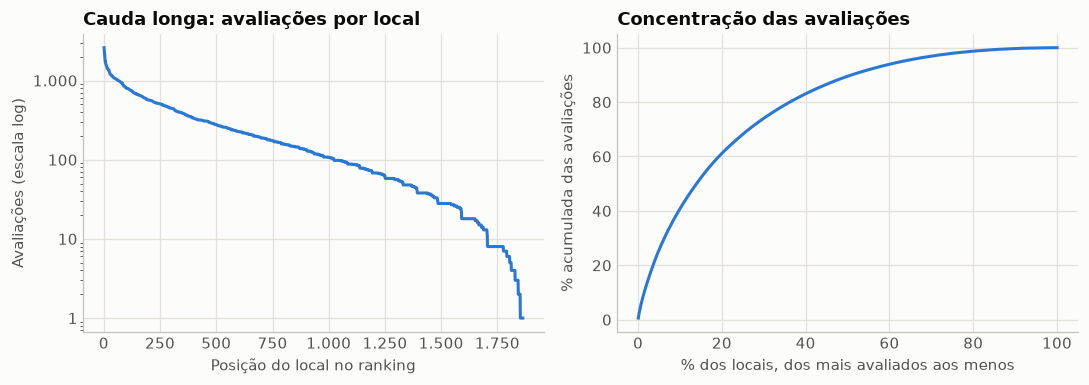

In [18]:
avaliacoes_por_local = limpas.groupby("gmap_id").size().sort_values(ascending=False)
acumulado = avaliacoes_por_local.cumsum() / avaliacoes_por_local.sum()
fracao_locais = np.arange(1, len(avaliacoes_por_local) + 1) / len(avaliacoes_por_local)

print(f"Índice de Gini: {numero_br(indice_gini(avaliacoes_por_local), 3)}")
print(f"Mediana de avaliações por local: {numero_br(avaliacoes_por_local.median())}; média: {numero_br(avaliacoes_por_local.mean(), 1)}")
display(
    pd.DataFrame(
        {
            "locais": [int(np.ceil(fatia * len(avaliacoes_por_local))) for fatia in [0.01, 0.1, 0.2, 0.5]],
            "fração das avaliações": [acumulado.iloc[int(np.ceil(fatia * len(acumulado))) - 1] for fatia in [0.01, 0.1, 0.2, 0.5]],
        },
        index=["1% mais avaliados", "10% mais avaliados", "20% mais avaliados", "50% mais avaliados"],
    ).round(3)
)
display(
    limpas.groupby("gmap_id")
    .size()
    .rename("avaliacoes")
    .sort_values(ascending=False)
    .head(10)
    .to_frame()
    .join(locais_limpos.set_index("gmap_id")[["name", "cidade", "categoria_principal"]])
    .reset_index(drop=True)
)

figura, (eixo_cauda, eixo_concentracao) = plt.subplots(1, 2, figsize=(10, 3.6))
eixo_cauda.plot(np.arange(1, len(avaliacoes_por_local) + 1), avaliacoes_por_local.values, color=COR_PRINCIPAL)
eixo_cauda.set_yscale("log")
eixo_cauda.set_title("Cauda longa: avaliações por local")
eixo_cauda.set_xlabel("Posição do local no ranking")
eixo_cauda.set_ylabel("Avaliações (escala log)")
eixo_br(eixo_cauda.xaxis)
eixo_br(eixo_cauda.yaxis)
eixo_concentracao.plot(fracao_locais * 100, acumulado.values * 100, color=COR_PRINCIPAL)
eixo_concentracao.set_title("Concentração das avaliações")
eixo_concentracao.set_xlabel("% dos locais, dos mais avaliados aos menos")
eixo_concentracao.set_ylabel("% acumulada das avaliações")
figura.tight_layout()
salvar(figura, "12_popularidade")
plt.show()

**Popularidade:** a atenção é concentrada, mas sem domínio extremo: o índice de Gini é 0,587, os 20% de locais mais avaliados têm 61,2% das avaliações e os 19 maiores (1%) têm 7,6%. A mediana de 123 avaliações por local, contra média de 230,6, mostra a cauda longa. Como metade dos locais tem 123 avaliações ou mais, a média das notas de boa parte do catálogo tem base suficiente.

,usuários com 5+ avaliações,locais com 5+ avaliações
count,18300.00,1811.00
mean,4.20,4.19
std,0.61,0.47
min,1.00,1.80
25%,3.83,3.94
50%,4.27,4.26
75%,4.67,4.53
max,5.00,5.00


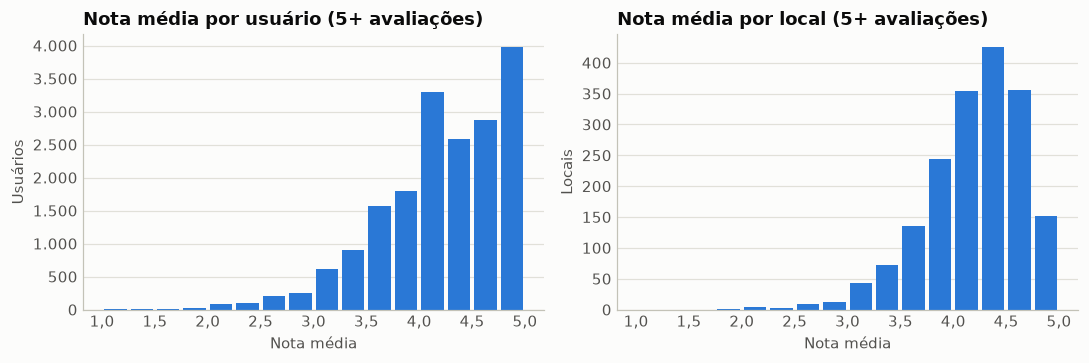

In [19]:
MINIMO_AVALIACOES = 5
por_usuario = limpas.groupby("user_id")["rating"].agg(["size", "mean"])
por_local = limpas.groupby("gmap_id")["rating"].agg(["size", "mean"])
usuarios_filtrados = por_usuario[por_usuario["size"] >= MINIMO_AVALIACOES]
locais_filtrados = por_local[por_local["size"] >= MINIMO_AVALIACOES]

display(
    pd.DataFrame(
        {
            f"usuários com {MINIMO_AVALIACOES}+ avaliações": usuarios_filtrados["mean"].describe(),
            f"locais com {MINIMO_AVALIACOES}+ avaliações": locais_filtrados["mean"].describe(),
        }
    ).round(2)
)

figura, (eixo_usuarios, eixo_locais) = plt.subplots(1, 2, figsize=(10, 3.4))
faixas = np.arange(1, 5.01, 0.25)
eixo_usuarios.hist(usuarios_filtrados["mean"], bins=faixas, color=COR_PRINCIPAL, rwidth=0.85)
eixo_usuarios.set_title(f"Nota média por usuário ({MINIMO_AVALIACOES}+ avaliações)")
eixo_usuarios.set_ylabel("Usuários")
eixo_locais.hist(locais_filtrados["mean"], bins=faixas, color=COR_PRINCIPAL, rwidth=0.85)
eixo_locais.set_title(f"Nota média por local ({MINIMO_AVALIACOES}+ avaliações)")
eixo_locais.set_ylabel("Locais")
for eixo in (eixo_usuarios, eixo_locais):
    eixo.set_xlabel("Nota média")
    eixo.grid(axis="x", visible=False)
    eixo_br(eixo.xaxis, 1)
    eixo_br(eixo.yaxis)
figura.tight_layout()
salvar(figura, "13_nota_media")
plt.show()

**Nota média por usuário e por local:** considerando quem tem ao menos 5 avaliações (18.300 usuários e 1.811 locais), as médias são parecidas, 4,20 e 4,19. Os usuários variam mais (desvio-padrão de 0,61, contra 0,47 dos locais) e formam um pico perto da média 5, de pessoas que dão quase só notas máximas. Os locais também variam, o que abre espaço para usar a qualidade do local como sinal.

Categorias principais no recorte: 98
As 20 maiores têm 87,6% das avaliações


,avaliacoes,locais,nota_media
categoria_principal,,,
Fast food restaurant,74061,152,3.72
Restaurant,45540,250,4.07
Mexican restaurant,34124,103,4.28
American restaurant,31008,115,4.31
Steak house,26359,50,4.32
Pizza restaurant,21493,94,4.20
Bar & grill,19404,82,4.34
Coffee shop,16209,110,4.37
Bar,14722,169,4.25


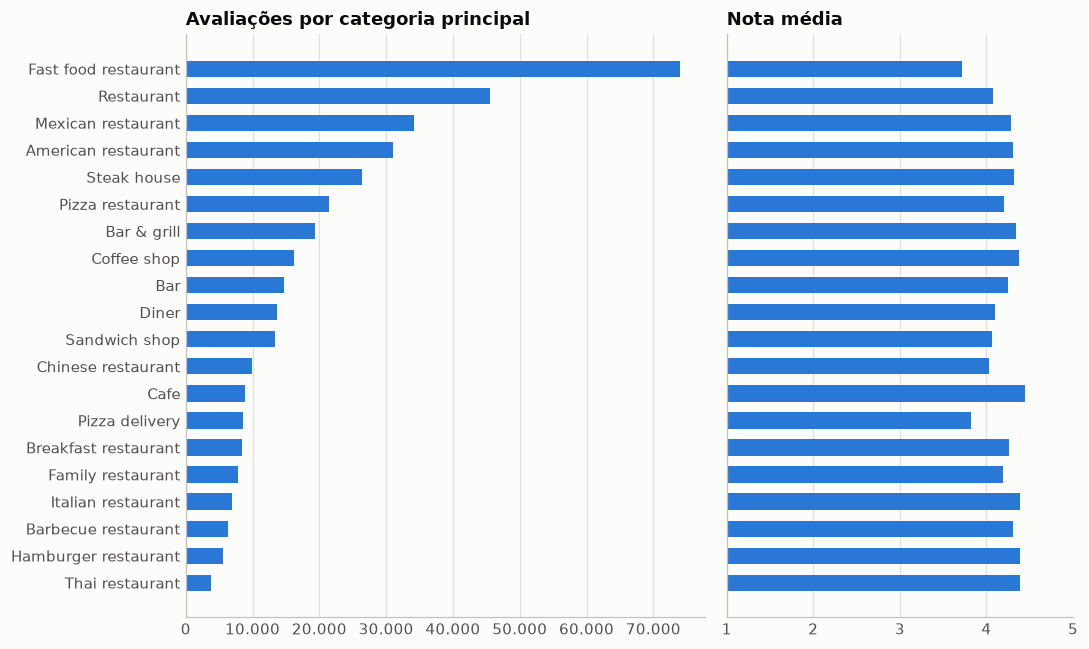

In [20]:
categorias = (
    base.groupby("categoria_principal")
    .agg(avaliacoes=("rating", "size"), locais=("gmap_id", "nunique"), nota_media=("rating", "mean"))
    .sort_values("avaliacoes", ascending=False)
)
top_categorias = categorias.head(20)
print(f"Categorias principais no recorte: {inteiro(len(categorias))}")
print(f"As 20 maiores têm {percentual(top_categorias['avaliacoes'].sum() / len(base))} das avaliações")
display(top_categorias.round(2))

figura, (eixo_quantidade, eixo_nota) = plt.subplots(1, 2, figsize=(10, 6), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
nomes = top_categorias.index[::-1]
eixo_quantidade.barh(nomes, top_categorias["avaliacoes"].values[::-1], color=COR_PRINCIPAL, height=0.6)
eixo_quantidade.set_title("Avaliações por categoria principal")
eixo_quantidade.grid(axis="y", visible=False)
eixo_br(eixo_quantidade.xaxis)
eixo_nota.barh(nomes, top_categorias["nota_media"].values[::-1], color=COR_PRINCIPAL, height=0.6)
eixo_nota.set_title("Nota média")
eixo_nota.set_xlim(1, 5)
eixo_nota.grid(axis="y", visible=False)
eixo_br(eixo_nota.xaxis)
figura.tight_layout()
salvar(figura, "14_categorias")
plt.show()

**Categorias:** as 20 maiores das 98 categorias principais têm 87,6% das avaliações. Fast food é a mais avaliada (74.061) e tem a menor nota entre elas (3,72), seguida de Pizza delivery (3,82); Cafe tem a maior (4,45). A categoria mais avaliada não é a mais bem avaliada, e os dados mostram diferenças de nota entre tipos de local. As categorias estão no idioma original da base.

As 15 maiores cidades têm 82,7% das avaliações


,avaliacoes,locais,nota_media
cidade,,,
Cheyenne,95091,235,4.07
Casper,56496,200,4.20
Jackson,38473,117,4.26
Laramie,28718,112,4.17
Gillette,24057,103,4.10
Rock Springs,23923,95,4.03
Sheridan,17814,85,4.19
Cody,17278,73,4.15
Evanston,11367,51,4.08


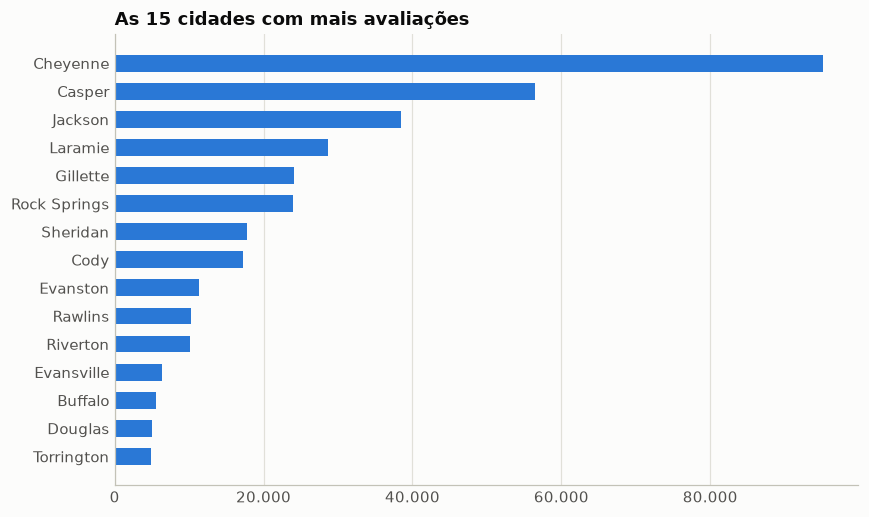

In [21]:
cidades = (
    base.groupby("cidade")
    .agg(avaliacoes=("rating", "size"), locais=("gmap_id", "nunique"), nota_media=("rating", "mean"))
    .sort_values("avaliacoes", ascending=False)
)
top_cidades = cidades.head(15)
print(f"As 15 maiores cidades têm {percentual(top_cidades['avaliacoes'].sum() / len(base))} das avaliações")
display(top_cidades.round(2))

figura, eixo = plt.subplots(figsize=(8, 4.8))
eixo.barh(top_cidades.index[::-1], top_cidades["avaliacoes"].values[::-1], color=COR_PRINCIPAL, height=0.6)
eixo.set_title("As 15 cidades com mais avaliações")
eixo.grid(axis="y", visible=False)
eixo_br(eixo.xaxis)
figura.tight_layout()
salvar(figura, "15_cidades")
plt.show()

**Cidades:** as 15 maiores das 115 cidades têm 82,7% das avaliações, com Cheyenne (95.091), Casper (56.496) e Jackson (38.473) à frente. Evansville, vizinha de Casper, aparece com 6.383: locais muito próximos podem estar em cidades com nomes diferentes, um dos motivos para comparar cidade e distância na Fase 3.

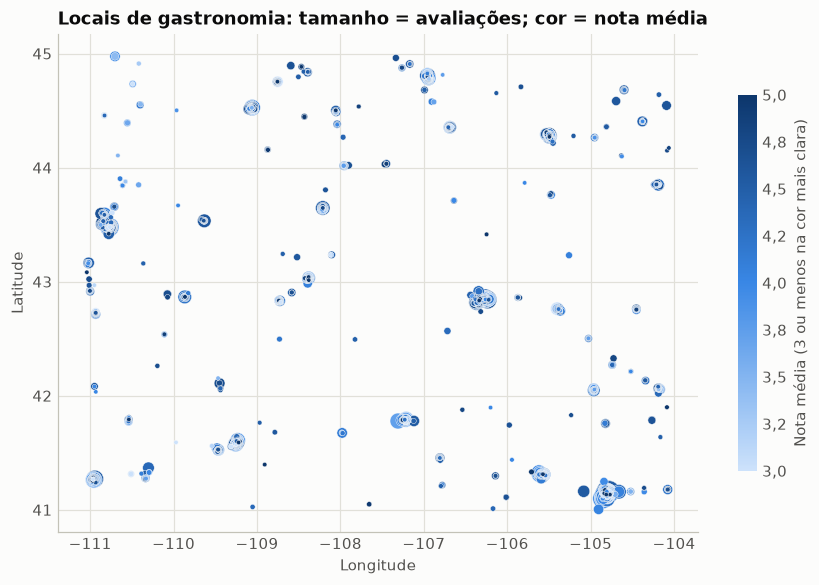

In [22]:
resumo_locais = (
    limpas.groupby("gmap_id")
    .agg(avaliacoes=("rating", "size"), nota_media=("rating", "mean"))
    .join(locais_limpos.set_index("gmap_id")[["latitude", "longitude"]])
    .sort_values("avaliacoes", ascending=False)
)

figura, eixo = plt.subplots(figsize=(8, 6))
pontos = eixo.scatter(
    resumo_locais["longitude"],
    resumo_locais["latitude"],
    s=8 + resumo_locais["avaliacoes"] / 12,
    c=resumo_locais["nota_media"].clip(3, 5),
    cmap=ESCALA_SEQUENCIAL,
    vmin=3,
    vmax=5,
    linewidths=0.3,
    edgecolors="#fcfcfb",
)
eixo.set_aspect(1 / np.cos(np.radians(43)))
eixo.set_title("Locais de gastronomia: tamanho = avaliações; cor = nota média")
eixo.set_xlabel("Longitude")
eixo.set_ylabel("Latitude")
eixo.set_xticks(range(-111, -103))
eixo.set_yticks(range(41, 46))
legenda_cor = figura.colorbar(pontos, ax=eixo, shrink=0.6, label="Nota média (3 ou menos na cor mais clara)")
eixo_br(legenda_cor.ax.yaxis, 1)
legenda_cor.outline.set_visible(False)
figura.tight_layout()
salvar(figura, "16_mapa_locais")
plt.show()

**Mapa:** os locais formam aglomerados isolados nas cidades, com grandes áreas vazias entre eles. Isso sugere que a localização deve pesar na recomendação, hipótese que a seção 1.5 mede. A cor não mostra uma região com notas sistematicamente melhores: locais bons e ruins se misturam em cada cidade.

,avaliacoes,nota_media
ano,,
2008,5,3.800
2009,14,3.786
2010,69,3.667
2011,257,3.864
2012,547,3.870
2013,952,3.911
2014,1190,3.697
2015,3038,3.810
2016,13623,4.000


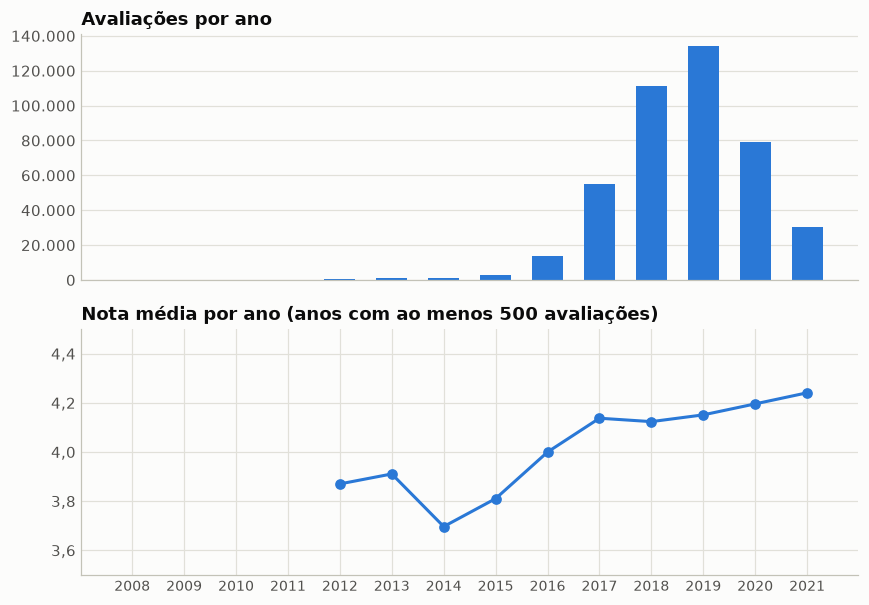

Avaliações por mês na pandemia e no fim da coleta:


,avaliações
data,
2020-01,8980
2020-02,9357
2020-03,5076
2020-04,906
2020-05,3448
2020-06,6640


,avaliações
data,
2021-03,7062
2021-04,7215
2021-05,3476
2021-06,709
2021-07,263
2021-08,151
2021-09,6


In [23]:
por_ano = base.groupby("ano").agg(avaliacoes=("rating", "size"), nota_media=("rating", "mean"))
display(por_ano.round(3))

figura, (eixo_quantidade, eixo_nota) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
eixo_quantidade.bar(por_ano.index, por_ano["avaliacoes"], color=COR_PRINCIPAL, width=0.6)
eixo_quantidade.set_title("Avaliações por ano")
eixo_quantidade.grid(axis="x", visible=False)
eixo_br(eixo_quantidade.yaxis)
confiaveis = por_ano[por_ano["avaliacoes"] >= 500]
eixo_nota.plot(confiaveis.index, confiaveis["nota_media"], color=COR_PRINCIPAL, marker="o", markersize=6)
eixo_nota.set_title("Nota média por ano (anos com ao menos 500 avaliações)")
eixo_nota.set_ylim(3.5, 4.5)
eixo_br(eixo_nota.yaxis, 1)
eixo_nota.set_xticks(por_ano.index)
eixo_nota.tick_params(axis="x", labelsize=9)
figura.tight_layout()
salvar(figura, "17_avaliacoes_por_ano")
plt.show()

mensal = base.groupby(base["data"].dt.to_period("M")).size().rename("avaliações").to_frame()
print("Avaliações por mês na pandemia e no fim da coleta:")
display(mensal.loc["2020-01":"2020-06"])
display(mensal.loc["2021-03":"2021-09"])

**Tempo:** 2018 e 2019 têm 57,1% das avaliações, e os anos anteriores a 2016 têm muito pouco. A nota média sobe de 3,70 em 2014 para 4,24 em 2021. Dois eventos viram limitações do trabalho:

- **Pandemia:** queda de 9.357 avaliações em fevereiro de 2020 para 906 em abril, com volta a 6.640 em junho.
- **Fim da coleta:** de 7.215 em abril de 2021 para 709 em junho e só 6 em setembro.

Avaliações nas cidades turísticas: 61.147 (14,2%)
Todas as cidades, período inteiro: julho / fevereiro = 1,45
Todas as cidades, 2017 a 2019: julho / fevereiro = 2,05
Turísticas, período inteiro: julho / fevereiro = 2,34
Turísticas, 2017 a 2019: julho / fevereiro = 3,29


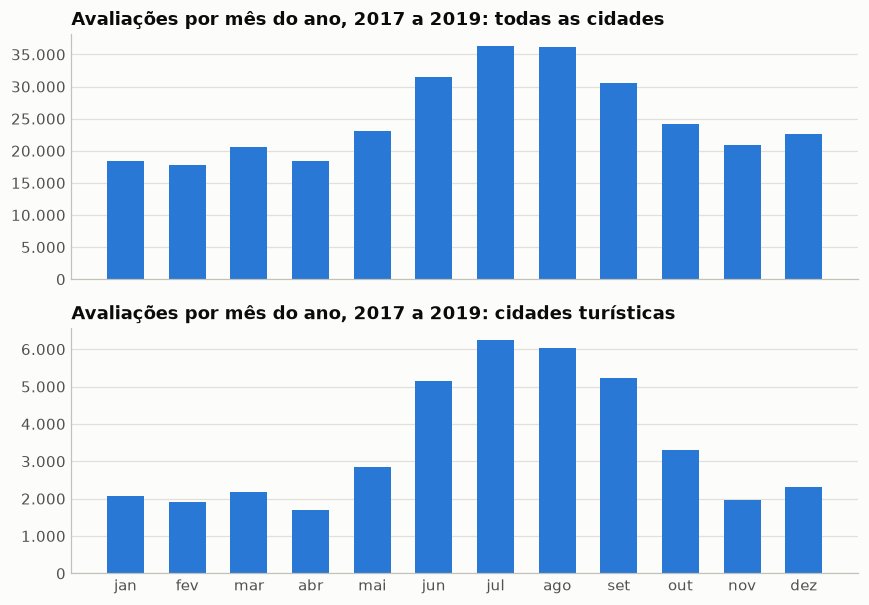

In [24]:
CIDADES_TURISTICAS = ["Jackson", "Cody", "Moran", "Alta", "Wapiti", "Dubois", "Pinedale"]
NOMES_MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
turisticas = base["cidade"].isin(CIDADES_TURISTICAS)
anos_completos = base["ano"].between(2017, 2019)


def por_mes(tabela):
    return tabela.groupby("mes").size().reindex(range(1, 13), fill_value=0)


print(f"Avaliações nas cidades turísticas: {inteiro(turisticas.sum())} ({percentual(turisticas.mean())})")
for nome, serie in [
    ("Todas as cidades, período inteiro", por_mes(base)),
    ("Todas as cidades, 2017 a 2019", por_mes(base[anos_completos])),
    ("Turísticas, período inteiro", por_mes(base[turisticas])),
    ("Turísticas, 2017 a 2019", por_mes(base[anos_completos & turisticas])),
]:
    print(f"{nome}: julho / fevereiro = {numero_br(serie[7] / serie[2], 2)}")

figura, (eixo_geral, eixo_turisticas) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
eixo_geral.bar(NOMES_MESES, por_mes(base[anos_completos]), color=COR_PRINCIPAL, width=0.6)
eixo_geral.set_title("Avaliações por mês do ano, 2017 a 2019: todas as cidades")
eixo_turisticas.bar(NOMES_MESES, por_mes(base[anos_completos & turisticas]), color=COR_PRINCIPAL, width=0.6)
eixo_turisticas.set_title("Avaliações por mês do ano, 2017 a 2019: cidades turísticas")
for eixo in (eixo_geral, eixo_turisticas):
    eixo.grid(axis="x", visible=False)
    eixo_br(eixo.yaxis)
figura.tight_layout()
salvar(figura, "18_avaliacoes_por_mes")
plt.show()

**Sazonalidade:** o gráfico usa 2017 a 2019, anos completos e sem pandemia, porque no período inteiro a pandemia e o fim da coleta distorcem os meses. Nesses anos, julho tem 2,05 vezes as avaliações de fevereiro; nas cidades turísticas, que somam 14,2% da base, 3,29 vezes. No período inteiro, as razões caem para 1,45 e 2,34. Essa diferença entre estações é o motivo de a validação cobrir um ano completo.

Locais sem preço: 691 (37,1%)
Locais com MISC: 1.853 (99,5%); atributos distintos: 136


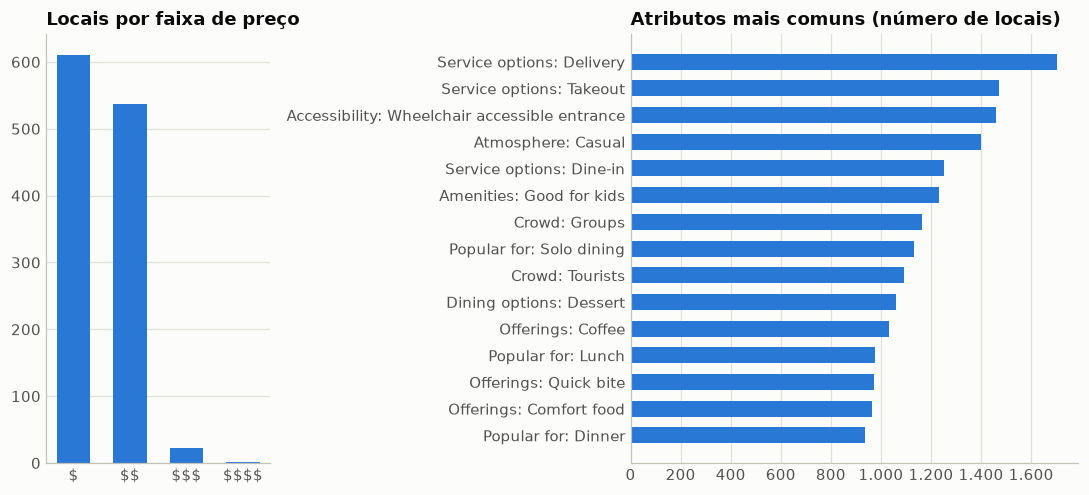

In [25]:
precos = locais_limpos["preco_nivel"].value_counts().sort_index()
atributos = pd.Series([atributo for misc in locais_limpos["MISC"] for atributo in atributos_do_local(misc)])
mais_comuns = atributos.value_counts().head(15)
tem_misc = locais_limpos["MISC"].map(lambda misc: isinstance(misc, dict))

print(f"Locais sem preço: {inteiro(locais_limpos['preco_nivel'].isna().sum())} ({percentual(locais_limpos['preco_nivel'].isna().mean())})")
print(f"Locais com MISC: {inteiro(tem_misc.sum())} ({percentual(tem_misc.mean())}); atributos distintos: {inteiro(atributos.nunique())}")

figura, (eixo_preco, eixo_atributos) = plt.subplots(1, 2, figsize=(10, 4.6), gridspec_kw={"width_ratios": [1, 2]})
rotulos_preco = ["\\$" * int(nivel) for nivel in precos.index]
eixo_preco.bar(rotulos_preco, precos.values, color=COR_PRINCIPAL, width=0.6)
eixo_preco.set_title("Locais por faixa de preço")
eixo_preco.grid(axis="x", visible=False)
eixo_br(eixo_preco.yaxis)
eixo_atributos.barh(mais_comuns.index[::-1], mais_comuns.values[::-1], color=COR_PRINCIPAL, height=0.6)
eixo_atributos.set_title("Atributos mais comuns (número de locais)")
eixo_atributos.grid(axis="y", visible=False)
eixo_br(eixo_atributos.xaxis)
figura.tight_layout()
salvar(figura, "19_preco_atributos")
plt.show()

**Preço e atributos:** 37,1% dos locais não têm preço, e quase todos os demais estão nas faixas \$ e \$\$, então o preço diferencia pouco. Quase todos os locais (99,5%) têm atributos em `MISC`, com 136 valores distintos. Entre os 15 mais comuns, 10 vêm de grupos que derivam do comportamento dos clientes (Atmosphere, Crowd, Popular for, Dining options, Offerings); a seção 1.5 examina esse viés antes de definir o que entra no vetor de conteúdo. Os atributos estão no idioma original da base.

Avaliações com comentário: 58,7%


,fração com comentário,tamanho mediano (caracteres)
rating,,
1,0.772,158.0
2,0.668,122.0
3,0.485,68.0
4,0.501,53.0
5,0.610,57.0


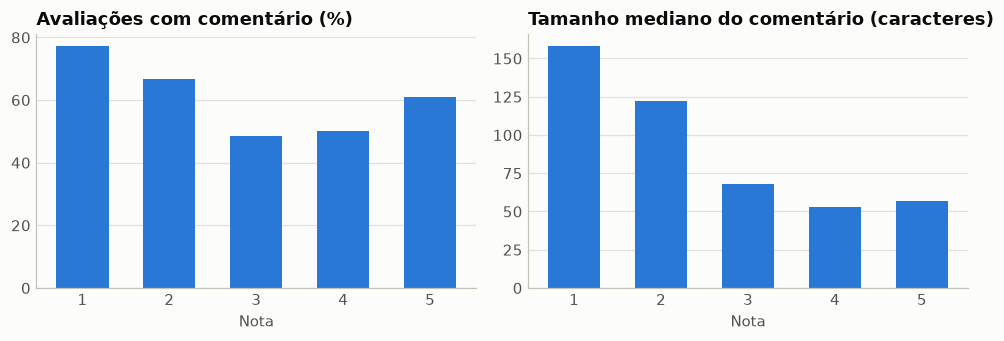

In [26]:
com_texto = limpas[limpas["tem_texto"]]
texto_por_nota = pd.DataFrame(
    {
        "fração com comentário": limpas.groupby("rating")["tem_texto"].mean(),
        "tamanho mediano (caracteres)": com_texto.groupby("rating")["text"].apply(lambda textos: textos.str.len().median()),
    }
)
print(f"Avaliações com comentário: {percentual(limpas['tem_texto'].mean())}")
display(texto_por_nota.round(3))

figura, (eixo_fracao, eixo_tamanho) = plt.subplots(1, 2, figsize=(9, 3.2))
eixo_fracao.bar(texto_por_nota.index, texto_por_nota["fração com comentário"] * 100, color=COR_PRINCIPAL, width=0.6)
eixo_fracao.set_title("Avaliações com comentário (%)")
eixo_tamanho.bar(texto_por_nota.index, texto_por_nota["tamanho mediano (caracteres)"], color=COR_PRINCIPAL, width=0.6)
eixo_tamanho.set_title("Tamanho mediano do comentário (caracteres)")
for eixo in (eixo_fracao, eixo_tamanho):
    eixo.set_xlabel("Nota")
    eixo.grid(axis="x", visible=False)
figura.tight_layout()
salvar(figura, "1a_texto")
plt.show()

**Texto:** 58,7% das avaliações têm comentário. Quem dá nota 1 comenta mais (77,2%, contra 48,5% na nota 3) e escreve mais (mediana de 158 caracteres, contra 53 na nota 4). O texto não entra no modelo, porque um local recém-cadastrado não teria comentários.

## 1.5 Análises para as decisões

Todas as células desta seção usam só as avaliações anteriores ao corte de teste (quantil 80% das datas), para que nenhuma decisão olhe o período de teste. Os metadados dos locais são uma foto de 2021; esse limite é tratado na análise de viés. Cada análise termina com a decisão que ela apoia.

In [27]:
corte_teste = limpas["data"].quantile(0.8)
pre = base[base["data"] < corte_teste]
print(f"Corte de teste: {corte_teste:%d/%m/%Y}")
print(f"Avaliações antes do corte: {inteiro(len(pre))}; a partir dele: {inteiro(len(base) - len(pre))}")
print(f"Usuários antes do corte: {inteiro(pre['user_id'].nunique())}; locais: {inteiro(pre['gmap_id'].nunique())}")

Corte de teste: 31/03/2020
Avaliações antes do corte: 343.697; a partir dele: 85.925
Usuários antes do corte: 140.895; locais: 1.760


In [28]:
linhas_core = []
for k in [1, 3, 5, 10, 20]:
    nucleo_k = k_core(pre, k)
    n_usuarios, n_locais = nucleo_k["user_id"].nunique(), nucleo_k["gmap_id"].nunique()
    linhas_core.append(
        {
            "usuários": n_usuarios,
            "locais": n_locais,
            "avaliações": len(nucleo_k),
            "fração das avaliações": len(nucleo_k) / len(pre),
            "densidade": len(nucleo_k) / (n_usuarios * n_locais) if n_usuarios else 0,
        }
    )
pd.DataFrame(linhas_core, index=pd.Index([1, 3, 5, 10, 20], name="k")).round(5)

,usuários,locais,avaliações,fração das avaliações,densidade
k,,,,,
1,140895,1760,343697,1.00000,0.00139
3,28281,1667,211258,0.61466,0.00448
5,14871,1560,166002,0.48299,0.00716
10,5773,1275,105615,0.30729,0.01435
20,875,356,26262,0.07641,0.08431


**k-core:** exigir 5 avaliações por usuário e por local mantém 14.871 usuários e 48,3% das avaliações; exigir 20 mantém 875 usuários e 7,6%. A densidade continua baixa até k = 10 (1,4%).

**Decisão que apoia:** técnicas colaborativas puras só atendem uma pequena parte dos usuários, o que limita vizinhos e grafos.

In [29]:
gerador_vizinhos = np.random.default_rng(42)
nucleo = k_core(pre, 5)
usuarios_nucleo = matriz_binaria(nucleo["user_id"], nucleo["gmap_id"])
locais_nucleo = usuarios_nucleo.T.tocsr()
amostra_usuarios = gerador_vizinhos.choice(usuarios_nucleo.shape[0], size=min(1000, usuarios_nucleo.shape[0]), replace=False)
suporte_usuarios = suporte_vizinhos(usuarios_nucleo, amostra_usuarios)
suporte_locais = suporte_vizinhos(locais_nucleo, np.arange(locais_nucleo.shape[0]))

pd.DataFrame(
    {
        "usuários (amostra de 1.000)": suporte_usuarios.median(),
        "locais (todos)": suporte_locais.median(),
    }
).rename(
    index={
        "vizinhos_2+": "Vizinhos com ≥ 2 em comum (mediana)",
        "vizinhos_3+": "Vizinhos com ≥ 3 em comum (mediana)",
        "vizinhos_5+": "Vizinhos com ≥ 5 em comum (mediana)",
        "vizinhos_10+": "Vizinhos com ≥ 10 em comum (mediana)",
        "suporte_vizinho": "Itens em comum com o 20º vizinho (mediana)",
    }
)

,usuários (amostra de 1.000),locais (todos)
Vizinhos com ≥ 2 em comum (mediana),375.0,139.0
Vizinhos com ≥ 3 em comum (mediana),119.5,88.0
Vizinhos com ≥ 5 em comum (mediana),9.0,51.0
Vizinhos com ≥ 10 em comum (mediana),0.0,19.0
Itens em comum com o 20º vizinho (mediana),4.0,9.0


**Sobreposição no 5-core:** mesmo no núcleo mais ativo, o 20º vizinho de um usuário tem mediana de 4 locais em comum, e o usuário mediano não tem nenhum vizinho com 10 ou mais. O 20º vizinho de um local tem 9 usuários em comum, e o local mediano tem 19 vizinhos com 10 ou mais.

**Decisão que apoia:** vizinhos por usuário são fracos; se houvesse uma alternativa colaborativa, seria vizinhos por item, que por isso fica como referência na Fase 3.

In [30]:
notas_por_usuario = pre.groupby("user_id")["rating"].agg(["size", "nunique"])
pd.DataFrame(
    {
        "usuários": [(notas_por_usuario["size"] >= k).sum() for k in [2, 3, 5, 10, 20]],
        "nota sempre igual": [
            notas_por_usuario.loc[notas_por_usuario["size"] >= k, "nunique"].eq(1).mean() for k in [2, 3, 5, 10, 20]
        ],
    },
    index=pd.Index([2, 3, 5, 10, 20], name="com ao menos k avaliações"),
).round(3)

,usuários,nota sempre igual
com ao menos k avaliações,,
2,48009,0.330
3,28294,0.201
5,14925,0.111
10,5939,0.047
20,1758,0.023


**Notas constantes:** 20,1% dos usuários com 3 ou mais avaliações e 11,1% dos com 5 ou mais dão sempre a mesma nota.

**Decisão que apoia:** centro 3 no perfil. Centrar pela média do usuário zeraria o perfil dessas pessoas.

In [31]:
contagem_usuario = pre.groupby("user_id")["rating"].transform("size")
pd.DataFrame(
    {
        "Todos os usuários": decompor_variancia(pre),
        "Usuários com 5 ou mais avaliações": decompor_variancia(pre[contagem_usuario >= 5]),
    }
).rename(
    index={
        "local": "Local",
        "local_ajustado": "Local (ajustado)",
        "local_usuario": "Local + usuário",
        "local_usuario_ajustado": "Local + usuário (ajustado)",
    }
).round(3)

,Todos os usuários,Usuários com 5 ou mais avaliações
Local,0.115,0.112
Local (ajustado),0.110,0.103
Local + usuário,0.646,0.366
Local + usuário (ajustado),0.395,0.296


**Decomposição da variância:** o local explica 11,5% da variância da nota. Somando o usuário, o valor bruto chega a 64,6%, mas esse número é inflado por quem tem uma única avaliação; ajustado pelo número de parâmetros, cai para 39,5%. Entre usuários com 5 ou mais avaliações, são 36,6% brutos e 29,6% ajustados, a medida mais confiável.

**Decisão que apoia:** a maior parte da nota não é explicada por local nem por usuário, então o espaço para personalização é pequeno. O viés do usuário entra na previsão de nota.

In [32]:
data_mediana = pre["data"].median()
primeira_metade = pre[pre["data"] < data_mediana].groupby("gmap_id")["rating"].agg(["size", "mean"])
segunda_metade = pre[pre["data"] >= data_mediana].groupby("gmap_id")["rating"].agg(["size", "mean"])
nos_dois = primeira_metade.join(segunda_metade, lsuffix="_1", rsuffix="_2", how="inner")
nos_dois = nos_dois[(nos_dois["size_1"] >= 10) & (nos_dois["size_2"] >= 10)]
estabilidade = spearmanr(nos_dois["mean_1"], nos_dois["mean_2"]).statistic
print(f"Data que divide os períodos: {data_mediana:%d/%m/%Y}")
print(f"Locais com 10 ou mais avaliações nos dois períodos: {inteiro(len(nos_dois))}")
print(f"Spearman da média do local entre os períodos: {numero_br(estabilidade, 3)}")

Data que divide os períodos: 11/11/2018
Locais com 10 ou mais avaliações nos dois períodos: 1.279
Spearman da média do local entre os períodos: 0,833


**Estabilidade do escore:** entre os 1.279 locais com ao menos 10 avaliações em cada período, a correlação de Spearman da média é 0,833.

**Decisão que apoia:** usar o escore calculado no treino, porque a qualidade relativa do local se mantém ao longo do tempo.

In [33]:
locais_pre = pre.groupby("gmap_id")["rating"].agg(["size", "mean"])
locais_pre = locais_pre[locais_pre["size"] >= 5]
correlacao_popularidade = spearmanr(locais_pre["mean"], locais_pre["size"]).statistic
print(f"Locais com 5 ou mais avaliações: {inteiro(len(locais_pre))}")
print(f"Spearman entre nota média e número de avaliações: {numero_br(correlacao_popularidade, 3)}")

Locais com 5 ou mais avaliações: 1.694
Spearman entre nota média e número de avaliações: -0,128


**Nota × popularidade:** a correlação de Spearman é −0,128: locais mais avaliados tendem a ter nota um pouco menor.

**Decisão que apoia:** qualidade e popularidade medem coisas diferentes e entram como dois escores separados.

In [34]:
print(f"Avaliações com nota 4 ou 5: {percentual((pre['rating'] >= 4).mean())}")
print(f"Avaliações com nota 5: {percentual((pre['rating'] == 5).mean())}")

Avaliações com nota 4 ou 5: 77,6%
Avaliações com nota 5: 54,2%


**Conversão × consumo:** 77,6% das avaliações têm nota 4 ou 5, e 54,2% têm nota 5. A maior parte do que é consumido conta como conversão.

**Decisão que apoia:** o critério duplo. A conversão mede sobretudo aonde a pessoa vai, então a AUC de gosto é necessária para medir se ela gostou.

In [35]:
gerador_jaccard = np.random.default_rng(42)
jaccard = matriz_jaccard(locais_limpos["category"].tolist())
posicoes = pre["gmap_id"].map({gmap_id: i for i, gmap_id in enumerate(locais_limpos["gmap_id"])}).to_numpy()
contagem_pre = np.bincount(posicoes, minlength=len(locais_limpos))
avaliados = np.flatnonzero(contagem_pre > 0)
decil = np.zeros(len(locais_limpos), dtype=int)
decil[avaliados] = pd.qcut(contagem_pre[avaliados], 10, labels=False, duplicates="drop")
locais_por_decil = {d: np.flatnonzero((decil == d) & (contagem_pre > 0)) for d in np.unique(decil[avaliados])}

reais, sorteados, gostou_gostou, nao_gostou_gostou = [], [], [], []
tabela_pos = pd.DataFrame({"user_id": pre["user_id"].to_numpy(), "pos": posicoes, "gostou": pre["rating"].to_numpy() >= 4})
for _, grupo in tabela_pos.groupby("user_id", sort=False):
    if len(grupo) < 3:
        continue
    pos = grupo["pos"].to_numpy()
    gostou = grupo["gostou"].to_numpy()
    reais.append(media_entre_pares(jaccard, pos))
    substitutos = [gerador_jaccard.choice(locais_por_decil[decil[p]]) for p in pos]
    sorteados.append(media_entre_pares(jaccard, substitutos))
    if gostou.sum() >= 2 and (~gostou).sum() >= 1:
        gostou_gostou.append(media_entre_pares(jaccard, pos[gostou]))
        nao_gostou_gostou.append(jaccard[np.ix_(pos[~gostou], pos[gostou])].mean())

reais, sorteados = np.array(reais), np.array(sorteados)
gostou_gostou, nao_gostou_gostou = np.array(gostou_gostou), np.array(nao_gostou_gostou)
diferenca_sorteio = ic_bootstrap(reais - sorteados)
diferenca_gosto = ic_bootstrap(gostou_gostou - nao_gostou_gostou)
print(f"Usuários com 3 ou mais avaliações: {inteiro(len(reais))}")
print(f"Jaccard entre locais do mesmo usuário: {numero_br(reais.mean(), 4)}; sorteados com a mesma popularidade: {numero_br(sorteados.mean(), 4)}")
print(f"Diferença: {numero_br(diferenca_sorteio[0], 4)} (IC 95%: {numero_br(diferenca_sorteio[1], 4)} a {numero_br(diferenca_sorteio[2], 4)})")
print(f"Usuários com notas boas e ruins: {inteiro(len(gostou_gostou))}")
print(f"Jaccard gostou × gostou: {numero_br(gostou_gostou.mean(), 4)}; não gostou × gostou: {numero_br(nao_gostou_gostou.mean(), 4)}")
print(f"Diferença: {numero_br(diferenca_gosto[0], 4)} (IC 95%: {numero_br(diferenca_gosto[1], 4)} a {numero_br(diferenca_gosto[2], 4)})")

Usuários com 3 ou mais avaliações: 28.294
Jaccard entre locais do mesmo usuário: 0,0963; sorteados com a mesma popularidade: 0,0851
Diferença: 0,0113 (IC 95%: 0,0100 a 0,0126)
Usuários com notas boas e ruins: 14.965
Jaccard gostou × gostou: 0,0878; não gostou × gostou: 0,0964
Diferença: -0,0086 (IC 95%: -0,0105 a -0,0068)


**Coerência de conteúdo:** os locais de um mesmo usuário se parecem um pouco mais que locais sorteados com a mesma popularidade (Jaccard de 0,0963 × 0,0851; diferença de 0,0113, IC 95% de 0,0100 a 0,0126). Mas o que a pessoa não gostou é mais parecido com o que ela gostou do que as coisas de que ela gostou entre si (0,0964 × 0,0878; diferença de −0,0086, IC 95% de −0,0105 a −0,0068).

**Decisão que apoia:** categorias dizem um pouco sobre aonde a pessoa vai e não indicam o gosto. Por isso o modelo precisa de mais que categorias, e o sinal de gosto deve vir sobretudo da qualidade do local.

In [36]:
com_cidade = pre[pre["cidade"].notna()].sort_values("data", kind="stable")
por_usuario_cidade = com_cidade.groupby(["user_id", "cidade"]).size().rename("n").reset_index()
resumo_cidades = por_usuario_cidade.groupby("user_id")["n"].agg(["sum", "max", "size"])
ativos = resumo_cidades[resumo_cidades["sum"] >= 3]
fracao_principal = ativos["max"] / ativos["sum"]
print(f"Usuários com 3 ou mais avaliações: {inteiro(len(ativos))}")
print(f"Fração das avaliações na cidade principal: mediana {percentual(fracao_principal.median())}, média {percentual(fracao_principal.mean())}")
print(f"Cidades por usuário: mediana {numero_br(ativos['size'].median())}, média {numero_br(ativos['size'].mean(), 2)}")
print(f"Usuários com todas as avaliações em uma só cidade: {percentual((ativos['size'] == 1).mean())}")

avaliacoes_antes = com_cidade.groupby("user_id").cumcount()
avaliacoes_na_cidade_antes = com_cidade.groupby(["user_id", "cidade"]).cumcount()
com_historico = com_cidade[avaliacoes_antes > 0]
cidade_nova = (avaliacoes_na_cidade_antes == 0)[avaliacoes_antes > 0]
print(f"Avaliações de usuários com histórico: {inteiro(len(com_historico))}")
print(f"Em cidade nunca visitada pelo usuário: {percentual(cidade_nova.mean())}")
print(f"Nota média em cidade nova: {numero_br(com_historico.loc[cidade_nova, 'rating'].mean(), 3)}; "
      f"em cidade conhecida: {numero_br(com_historico.loc[~cidade_nova, 'rating'].mean(), 3)}")

medias_por_usuario = com_historico.assign(nova=cidade_nova).groupby(["user_id", "nova"])["rating"].mean().unstack().dropna()
diferenca, inferior, superior = ic_bootstrap(medias_por_usuario[True] - medias_por_usuario[False])
print(f"Diferença pareada por usuário (nova - conhecida), {inteiro(len(medias_por_usuario))} usuários: "
      f"{numero_br(diferenca, 3)} (IC 95%: {numero_br(inferior, 3)} a {numero_br(superior, 3)})")

Usuários com 3 ou mais avaliações: 28.288
Fração das avaliações na cidade principal: mediana 75,0%, média 74,1%
Cidades por usuário: mediana 2, média 2,41
Usuários com todas as avaliações em uma só cidade: 33,6%


Avaliações de usuários com histórico: 202.751
Em cidade nunca visitada pelo usuário: 24,1%
Nota média em cidade nova: 4,202; em cidade conhecida: 4,147
Diferença pareada por usuário (nova - conhecida), 16.520 usuários: 0,023 (IC 95%: 0,007 a 0,038)


**Localidade:** entre usuários com 3 ou mais avaliações, a mediana é de 75,0% das avaliações na cidade principal, e 33,6% ficam em uma só cidade. Ainda assim, 24,1% das avaliações de quem tem histórico são em cidade nunca visitada. A nota nessas cidades é muito parecida com a das conhecidas (diferença pareada de 0,023, IC 95% de 0,007 a 0,038).

**Decisão que apoia:** um componente de local. Ele indica aonde a pessoa vai, não se ela vai gostar, e não pode ser um filtro rígido, pois excluiria cerca de um quarto das visitas.

Avaliações de usuários com histórico: 202.802


,km
P25,0.3
P50,1.3
P75,5.7
P90,144.9
P95,223.6
P99,419.5


,fração até essa distância
5,0.739
10,0.779
25,0.805
50,0.826
100,0.873
200,0.941


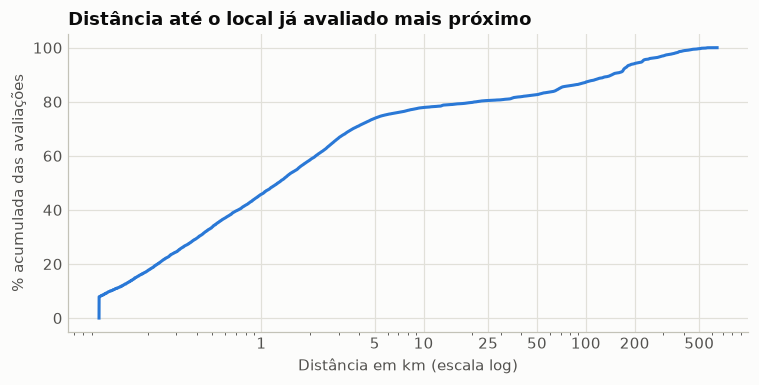

In [37]:
posicao_do_local = {gmap_id: i for i, gmap_id in enumerate(locais_limpos["gmap_id"])}
distancias = matriz_distancias_km(locais_limpos["latitude"], locais_limpos["longitude"])
ao_mais_proximo = distancia_ao_mais_proximo(pre, posicao_do_local, distancias)

print(f"Avaliações de usuários com histórico: {inteiro(len(ao_mais_proximo))}")
display(
    pd.DataFrame(
        {"km": np.percentile(ao_mais_proximo, [25, 50, 75, 90, 95, 99])},
        index=["P25", "P50", "P75", "P90", "P95", "P99"],
    ).round(1)
)
display(pd.DataFrame({"fração até essa distância": [(ao_mais_proximo <= km).mean() for km in [5, 10, 25, 50, 100, 200]]}, index=[5, 10, 25, 50, 100, 200]).round(3))

figura, eixo = plt.subplots(figsize=(7, 3.6))
ordenadas = np.sort(np.clip(ao_mais_proximo, 0.1, None))
eixo.plot(ordenadas, np.arange(1, len(ordenadas) + 1) / len(ordenadas) * 100, color=COR_PRINCIPAL)
eixo.set_xscale("log")
eixo.set_xticks([1, 5, 10, 25, 50, 100, 200, 500])
eixo.xaxis.set_minor_formatter(plt.NullFormatter())
eixo_br(eixo.xaxis)
eixo.set_title("Distância até o local já avaliado mais próximo")
eixo.set_xlabel("Distância em km (escala log)")
eixo.set_ylabel("% acumulada das avaliações")
figura.tight_layout()
salvar(figura, "1b_curva_distancia")
plt.show()

**Curva de distância:** a mediana até o local já avaliado mais próximo é de 1,3 km, e 77,9% ficam a até 10 km. Depois a curva quase para: de 10 km para 50 km só sobe de 77,9% para 82,6%, e o restante são viagens (P90 de 144,9 km). As pessoas ficam na cidade ou viajam para longe.

**Decisão que apoia:** valores de τ. A maior parte da mudança acontece até 10 km, então a Etapa 1 da Fase 3 passa a testar também τ = 10 km, além de 25, 50 e 100 km.

,locais,declaraveis,derivados,sem_preco,sem_misc
faixa,,,,,
0,103,5.476,8.544,0.903,0.019
1 a 9,170,4.235,6.700,0.835,0.018
10 a 49,383,5.183,9.645,0.650,0.005
50 a 199,648,7.894,12.531,0.276,0.005
200 ou mais,559,11.036,17.962,0.050,0.000


Spearman entre número de atributos (atributos) e popularidade: 0,567
Spearman entre número de atributos (declaraveis) e popularidade: 0,596
Spearman entre número de atributos (derivados) e popularidade: 0,492


,grupo,classe,locais,fração dos locais,Spearman com popularidade
0,Service options,declarável,1828,0.981,0.527
1,Accessibility,declarável,1512,0.812,0.551
2,Amenities,declarável,1435,0.770,0.455
3,Payments,declarável,770,0.413,0.310
4,Planning,declarável,459,0.246,0.231
5,From the business,declarável,81,0.043,-0.004
6,Popular for,derivado,1183,0.635,0.492
7,Highlights,derivado,1160,0.623,0.218
8,Crowd,derivado,1422,0.763,0.427
9,Atmosphere,derivado,1419,0.762,0.266


Valores do grupo Planning:


,locais
Planning: Accepts reservations,335
Planning: LGBTQ friendly,89
Planning: Quick visit,62
Planning: Dinner reservations recommended,52
Planning: Transgender safespace,50
Planning: Usually a wait,28
Planning: Lunch reservations recommended,2


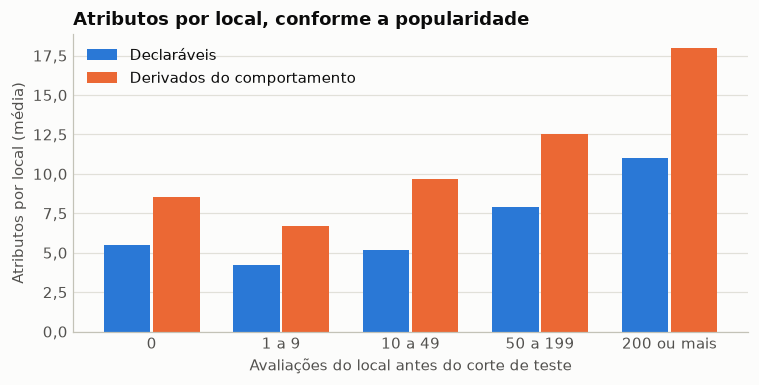

In [38]:
def atributos_por_grupo(misc, grupos):
    return sum(1 for atributo in atributos_do_local(misc) if atributo.split(": ")[0] in grupos)


vies = locais_limpos[["gmap_id", "MISC", "preco_nivel"]].copy()
vies["avaliacoes_pre"] = vies["gmap_id"].map(pre.groupby("gmap_id").size()).fillna(0).astype(int)
vies["declaraveis"] = vies["MISC"].map(lambda misc: atributos_por_grupo(misc, GRUPOS_DECLARAVEIS))
vies["derivados"] = vies["MISC"].map(lambda misc: atributos_por_grupo(misc, GRUPOS_DERIVADOS))
vies["atributos"] = vies["declaraveis"] + vies["derivados"]
vies["faixa"] = pd.cut(
    vies["avaliacoes_pre"], [-1, 0, 9, 49, 199, np.inf], labels=["0", "1 a 9", "10 a 49", "50 a 199", "200 ou mais"]
)
por_faixa = vies.groupby("faixa", observed=True).agg(
    locais=("gmap_id", "size"),
    declaraveis=("declaraveis", "mean"),
    derivados=("derivados", "mean"),
    sem_preco=("preco_nivel", lambda precos: precos.isna().mean()),
    sem_misc=("MISC", lambda misc: (~misc.map(lambda valor: isinstance(valor, dict))).mean()),
)
display(por_faixa.round(3))

com_avaliacao_pre = vies[vies["avaliacoes_pre"] > 0]
for coluna in ["atributos", "declaraveis", "derivados"]:
    correlacao = spearmanr(com_avaliacao_pre[coluna], com_avaliacao_pre["avaliacoes_pre"]).statistic
    print(f"Spearman entre número de atributos ({coluna}) e popularidade: {numero_br(correlacao, 3)}")

linhas_grupos = []
for classe, grupos in [("declarável", GRUPOS_DECLARAVEIS), ("derivado", GRUPOS_DERIVADOS), ("temporário", GRUPOS_TEMPORARIOS)]:
    for grupo in grupos:
        contagem_grupo = com_avaliacao_pre["MISC"].map(lambda misc: atributos_por_grupo(misc, [grupo]))
        todos = vies["MISC"].map(lambda misc: atributos_por_grupo(misc, [grupo]))
        linhas_grupos.append(
            {
                "grupo": grupo,
                "classe": classe,
                "locais": int((todos > 0).sum()),
                "fração dos locais": (todos > 0).mean(),
                "Spearman com popularidade": spearmanr(contagem_grupo, com_avaliacao_pre["avaliacoes_pre"]).statistic,
            }
        )
display(pd.DataFrame(linhas_grupos).round(3))

valores_planning = pd.Series([a for misc in vies["MISC"] for a in atributos_do_local(misc) if a.startswith("Planning: ")])
print("Valores do grupo Planning:")
display(valores_planning.value_counts().rename("locais").to_frame())

figura, eixo = plt.subplots(figsize=(7, 3.6))
posicoes_faixa = np.arange(len(por_faixa))
largura = 0.36
eixo.bar(posicoes_faixa - largura / 2 - 0.01, por_faixa["declaraveis"], largura, color=COR_PRINCIPAL, label="Declaráveis")
eixo.bar(posicoes_faixa + largura / 2 + 0.01, por_faixa["derivados"], largura, color=COR_SECUNDARIA, label="Derivados do comportamento")
eixo.set_xticks(posicoes_faixa, por_faixa.index)
eixo.set_title("Atributos por local, conforme a popularidade")
eixo.set_xlabel("Avaliações do local antes do corte de teste")
eixo.set_ylabel("Atributos por local (média)")
eixo.grid(axis="x", visible=False)
eixo_br(eixo.yaxis, 1)
eixo.legend(frameon=False)
figura.tight_layout()
salvar(figura, "1c_atributos_por_popularidade")
plt.show()

**Viés dos metadados:** o preço falta em 90,3% dos locais sem avaliação antes do corte e em 5,0% dos que têm 200 ou mais. Os atributos também crescem com a popularidade (Spearman de 0,567). **O achado novo é que retirar os grupos derivados não elimina esse viés:** os atributos declaráveis têm correlação até maior com a popularidade (0,596) que os derivados (0,492). Um local sem avaliações tem em média 5,5 atributos declaráveis, contra 11,0 dos mais populares. Além disso, o grupo Planning, classificado como declarável, inclui valores que dependem do comportamento dos clientes, como Usually a wait e Quick visit.

**Decisão que apoia:** preço fora do vetor, confirmado. A classificação declarável × derivado continua válida pelo critério de cadastro, mas não resolve o viés, então a seção 2.1 revê os valores do grupo Planning e a Etapa 3 da Fase 3 mede o efeito dos atributos no vetor.

In [39]:
linhas_novos = []
for quantil in [0.7, 0.8]:
    corte = pre["data"].quantile(quantil)
    passado = pre[pre["data"] < corte]
    futuro = pre[pre["data"] >= corte]
    historico = futuro["user_id"].map(passado.groupby("user_id").size()).fillna(0)
    locais_novos = ~futuro["gmap_id"].isin(passado["gmap_id"])
    linhas_novos.append(
        {
            "corte": f"{corte:%d/%m/%Y}",
            "avaliações no futuro": len(futuro),
            "usuário novo (0)": (historico == 0).mean(),
            "usuário com 1 ou 2": historico.between(1, 2).mean(),
            "usuário com 3 ou mais": (historico >= 3).mean(),
            "em local novo": locais_novos.mean(),
            "locais novos": futuro.loc[locais_novos, "gmap_id"].nunique(),
        }
    )
pd.DataFrame(linhas_novos, index=["70% das datas", "80% das datas"]).round(3)

,corte,avaliações no futuro,usuário novo (0),usuário com 1 ou 2,usuário com 3 ou mais,em local novo,locais novos
70% das datas,12/06/2019,103109,0.574,0.148,0.278,0.027,91
80% das datas,18/08/2019,68740,0.511,0.164,0.325,0.018,53


**Usuários e locais novos:** depois de cada corte, 51,1% a 57,4% das avaliações são de usuários sem nenhum histórico, e só 27,8% a 32,5% de quem tem 3 ou mais. Locais novos recebem 1,8% a 2,7% das avaliações, em 53 a 91 locais.

**Decisão que apoia:** o cenário 2 é o caso mais comum. O cenário 3 é pequeno em volume, mas tem locais novos reais em número suficiente para ser medido.

In [40]:
corte_validacao = corte_teste - pd.DateOffset(years=1)
treino_nota = pre[pre["data"] < corte_validacao]
validacao_nota = pre[pre["data"] >= corte_validacao]
media_global = treino_nota["rating"].mean()
media_do_local = treino_nota.groupby("gmap_id")["rating"].mean()
media_vies, vies_usuario, vies_local = ajustar_vieses(treino_nota)

real = validacao_nota["rating"].to_numpy(dtype=float)
previsoes = {
    "Média global": np.full(len(real), media_global),
    "Média do local": validacao_nota["gmap_id"].map(media_do_local).fillna(media_global).to_numpy(),
    "Média + vieses de local e usuário": (
        media_vies
        + validacao_nota["gmap_id"].map(vies_local).fillna(0)
        + validacao_nota["user_id"].map(vies_usuario).fillna(0)
    ).clip(1, 5).to_numpy(),
}
print(f"Corte: {corte_validacao:%d/%m/%Y}; treino: {inteiro(len(treino_nota))}; validação: {inteiro(len(validacao_nota))}")
print(f"Avaliações da validação com usuário conhecido no treino: {percentual(validacao_nota['user_id'].isin(treino_nota['user_id']).mean())}")
print(f"Avaliações da validação com local conhecido no treino: {percentual(validacao_nota['gmap_id'].isin(treino_nota['gmap_id']).mean())}")
display(pd.DataFrame({nome: erros_de_nota(real, previsto) for nome, previsto in previsoes.items()}).T.round(4))

nomes_previsoes = list(previsoes)
for pior, melhor in zip(nomes_previsoes, nomes_previsoes[1:]):
    ganho = (real - previsoes[pior]) ** 2 - (real - previsoes[melhor]) ** 2
    media_ganho, inferior, superior = ic_bootstrap(ganho, grupos=validacao_nota["user_id"].to_numpy())
    print(f"Redução do MSE de '{pior}' para '{melhor}': {numero_br(media_ganho, 4)} "
          f"(IC 95%: {numero_br(inferior, 4)} a {numero_br(superior, 4)})")

Corte: 31/03/2019; treino: 213.626; validação: 130.071


Avaliações da validação com usuário conhecido no treino: 40,0%


Avaliações da validação com local conhecido no treino: 96,5%


,MAE,MSE,RMSE
Média global,0.9387,1.4283,1.1951
Média do local,0.8876,1.3053,1.1425
Média + vieses de local e usuário,0.8745,1.2663,1.1253


Redução do MSE de 'Média global' para 'Média do local': 0,1230 (IC 95%: 0,1165 a 0,1294)


Redução do MSE de 'Média do local' para 'Média + vieses de local e usuário': 0,0390 (IC 95%: 0,0357 a 0,0423)


**Referências ingênuas de nota:** na divisão temporal que será usada na Fase 2, o RMSE cai de 1,1951 (média global) para 1,1425 (média do local) e 1,1253 (com vieses); as duas reduções têm intervalo de confiança que não inclui zero. O treino tem 213.626 avaliações, acima do mínimo de 150 mil previsto para a validação de um ano. Na validação, só 40,0% das avaliações são de usuários conhecidos, e 96,5% são de locais conhecidos.

**Decisão que apoia:** essas são as referências da previsão de nota. O ganho do viés do usuário existe, mas é pequeno, e a maioria das avaliações da validação vem de usuários sem histórico.

**Conclusão: técnica × evidência**

| Técnica | A favor | Contra | Cenário 2 | Cenário 3 |
|---|---|---|---|---|
| **Conteúdo e escores de produto (escolhida)** | Escore estável (0,833) e local explica 11,5% da nota | Categorias não indicam gosto; atributos carregam viés de popularidade | Atende, com cidade, escores e preferências declaradas | Atende, pelo conteúdo e pela localização do cadastro |
| Vizinhos próximos | Vizinhos por item têm suporte razoável (9 usuários em comum no 20º vizinho) | Por usuário, só 4 locais em comum, mesmo no 5-core | Não atende: 60,0% das avaliações da validação são de usuários desconhecidos | Não atende: local novo não tem avaliações |
| Bases de conhecimento | Não exige histórico | Não há regras de domínio prontas; usaria pouco as notas dos usuários | Atende | Atende, mas sem personalização pelas notas |
| Redes e grafos | Usa caminhos indiretos | Os usuários com uma só avaliação ficam na borda do grafo; `relative_results` foi coletado depois do corte | Não atende sem arestas | Não atende sem arestas |

As colunas "a favor" e "contra" vêm das análises acima. O que cada técnica atende nos cenários 2 e 3 é um argumento sobre o funcionamento da técnica, medido só na Fase 3.

**A técnica escolhida continua de pé**, por ser a única que atende sozinha os três cenários usando as notas dos usuários. O limite é claro: o sinal de gosto vem da qualidade do local, e a personalização tem pouco espaço. Isso não muda o rumo do trabalho.